In [1]:
%%capture
!pip install keras-cv

In [2]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


## Configuration

In [3]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow" # other options: tensorflow or torch
import json
import keras_cv
import keras
from keras import ops
import tensorflow as tf

import cv2
import pandas as pd
import numpy as np
from glob import glob
from tqdm.notebook import tqdm
import joblib

import matplotlib.pyplot as plt

In [4]:
class CFG:
    verbose = 1
    seed = 47
    neg_sample = 0.01 # Downsample negative calss
    pos_sample = 5.0  # Upsample positive class
    preset = "efficientnetv2_b2_imagenet"  # Name of pretrained classifier
    image_size = [128, 128]  # Input image size
    epochs = 8
    batch_size = 256
    lr_mode = "cos" # LR scheduler mode from one of "cos", "step", "exp"
    class_names = ['target']
    num_classes = 1

keras.utils.set_random_seed(CFG.seed)

In [5]:
ROOT = str(os.getcwd())
BASE_PATH = f"{ROOT}/drive/MyDrive/WAIT"
DATA_PATH = f"{BASE_PATH}/data/new"
MODEL_PATH = f"{BASE_PATH}/models/enhanced"
XAI_PATH = f"{MODEL_PATH}/enhanced/xai/test"
FS_PATH = f"{BASE_PATH}/models/enhanced/model-metadata"

# 📖 | Meta Data


### Enhanced

In [6]:
# Valid
df = pd.read_parquet(f'{DATA_PATH}/enhanced/enhanced_train_metadata_clean.parquet').ffill()

In [7]:
df.shape

(363483, 80)

# ⚖️ | Handle Class Imbalance

## Sample Data

There is a significant class imbalance in the dataset, with a large number of negative samples compared to positive samples. To address this issue, the negative class will be downsampled and upsample the positive class. To experiment with full dataset, simply adjust the `pos_sample` and `neg_sample` settings in `CFG`.

In [8]:
print("Class Distribution Before Sampling (%):")
display(df.target.value_counts(normalize=True)*100)

# Sampling
positive_df = df.query("target==0").sample(frac=CFG.neg_sample, random_state=CFG.seed)
negative_df = df.query("target==1").sample(frac=CFG.pos_sample, replace=True, random_state=CFG.seed)
df = pd.concat([positive_df, negative_df], axis=0).sample(frac=1.0)

print("\nCalss Distribution After Sampling (%):")
display(df.target.value_counts(normalize=True)*100)

Class Distribution Before Sampling (%):


,proportion
target,
0,99.899858
1,0.100142



Calss Distribution After Sampling (%):


,proportion
target,
0,66.611631
1,33.388369


## Class Weight

Even after downsampling the negative class and upsampling the positive class, there remains a significant class imbalance. To further address this imbalance during training, loss weighting will be used. This technique ensures that the model weights are updated more heavily for the positive samples, thereby reducing the bias towards the negative class. The following code computes the class weights for the loss:

In [9]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight('balanced', classes=np.unique(df['target']), y=df['target'])
class_weights = dict(enumerate(class_weights))
print("Class Weights:", class_weights)

Class Weights: {0: np.float64(0.7506196640044065), 1: np.float64(1.4975274725274725)}


# 🖼️ | Load Image Byte String


In [10]:
import h5py

training_validation_hdf5 = h5py.File(f"{DATA_PATH}/train-image.hdf5", 'r')

Byte String: b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00\x00\x01\x00\x01\x00\x00'....
Image:


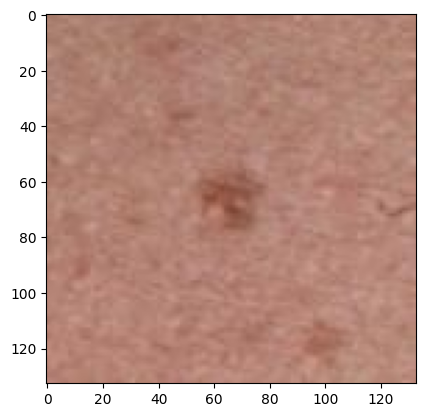

In [11]:
isic_id = df.isic_id.iloc[-10]

# Image as Byte String
byte_string = training_validation_hdf5[isic_id][()]
print(f"Byte String: {byte_string[:20]}....")

# Convert byte string to numpy array
nparr = np.frombuffer(byte_string, np.uint8)

print("Image:")
image = cv2.imdecode(nparr, cv2.IMREAD_COLOR)[...,::-1] # reverse last axis for bgr -> rgb
plt.imshow(image);

# 🔪 | Data Split

In the following code,the data will be splitted into `5` stratified folds and use the first fold for training and validation. It's important to note that `StratifiedGroupKFold` is being used to ensure that `patient_id`s do not overlap between the training and validation datasets. This prevents data leakage, where the model could potentially peak at data it should not have access to.

> **Note**: Data leakage can lead to artificially high validation scores that do not reflect real-world performance.


In [12]:
from sklearn.model_selection import StratifiedGroupKFold

df = df.reset_index(drop=True) # ensure continuous index
df["fold"] = -1
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=CFG.seed)
for i, (training_idx, validation_idx) in enumerate(sgkf.split(df, y=df.target, groups=df.patient_id)):
    df.loc[validation_idx, "fold"] = int(i)

# Use first fold for training and validation
validation_df = df.query("fold==0")
print(f"# Num Valid: {len(validation_df)}")

# Num Valid: 1068


In [13]:
# class distribution in training and validation
print("validation:", validation_df.target.value_counts(), sep='\n')

validation:
target
0    702
1    366
Name: count, dtype: int64


# 📊 | Tabular Features

### Enhanced


In [14]:
# Categorical features which will be one hot encoded
CATEGORICAL_COLUMNS = ["sex", "anatom_site_general", "tbp_tile_type",
                       "tbp_lv_location", "attribution"]

NEW_CATEGORICAL_COLUMNS =["combined_anatomical_site"]

# Numerical features which will be normalized
NUMERIC_COLUMNS = ["age_approx", "tbp_lv_nevi_confidence", "clin_size_long_diam_mm",
           "tbp_lv_areaMM2", "tbp_lv_area_perim_ratio", "tbp_lv_color_std_mean",
           "tbp_lv_deltaLBnorm", "tbp_lv_minorAxisMM"]

NEW_NUMERIC_COLUMNS = ["lesion_size_ratio", "lesion_shape_index", "hue_contrast",
        "luminance_contrast", "lesion_color_difference", "border_complexity",
         "3d_position_distance", "perimeter_to_area_ratio",
        "lesion_visibility_score", "symmetry_border_consistency", "color_consistency",

        "size_age_interaction", "hue_color_std_interaction", "lesion_severity_index",
        "shape_complexity_index", "color_contrast_index", "log_lesion_area",
        "normalized_lesion_size", "mean_hue_difference", "std_dev_contrast",
        "color_shape_composite_index", "3d_lesion_orientation", "overall_color_difference",
        "symmetry_perimeter_interaction", "comprehensive_lesion_index"]

# Tabular feature columns
FEAT_COLS = (CATEGORICAL_COLUMNS + NEW_CATEGORICAL_COLUMNS) + (NUMERIC_COLUMNS + NEW_NUMERIC_COLUMNS)

# 🍚 | DataLoader

This DataLoader is designed to process both `images` and tabular `features` simultaneously as inputs. It applies augmentations like `flip` and `cutout`, with additional options available such as random brightness, contrast, zoom, and rotation. Experimentation with different augmentations is encouraged. More details on the available augmentations in KerasCV can be found [here](https://keras.io/api/keras_cv/layers/preprocessing/).

In [15]:
def build_augmenter():
    # Define augmentations
    aug_layers = [
        keras_cv.layers.RandomCutout(height_factor=(0.02, 0.06), width_factor=(0.02, 0.06)),
        keras_cv.layers.RandomFlip(mode="horizontal"),
    ]

    # Apply augmentations to random samples
    aug_layers = [keras_cv.layers.RandomApply(x, rate=0.5) for x in aug_layers]

    # Build augmentation layer
    augmenter = keras_cv.layers.Augmenter(aug_layers)

    # Apply augmentations
    def augment(inp, label):
        images = inp["images"]
        aug_data = {"images": images}
        aug_data = augmenter(aug_data)
        inp["images"] = aug_data["images"]
        return inp, label
    return augment


def build_decoder(with_labels=True, target_size=CFG.image_size):
    def decode_image(inp):
        # Read jpeg image
        file_bytes = inp["images"]
        image = tf.io.decode_jpeg(file_bytes)

        # Resize
        image = tf.image.resize(image, size=target_size, method="area")

        # Rescale image
        image = tf.cast(image, tf.float32)
        # image /= 255.0

        # Reshape
        image = tf.reshape(image, [*target_size, 3])

        inp["images"] = image
        return inp

    def decode_label(label, num_classes):
        label = tf.cast(label, tf.float32)
        label = tf.reshape(label, [num_classes])
        return label

    def decode_with_labels(inp, label=None):
        inp = decode_image(inp)
        label = decode_label(label, CFG.num_classes)
        return (inp, label)

    return decode_with_labels if with_labels else decode_image


def build_dataset(
    isic_ids,
    hdf5,
    features,
    labels=None,
    batch_size=32,
    decode_fn=None,
    augment_fn=None,
    augment=False,
    shuffle=1024,
    cache=True,
    drop_remainder=False,
):
    if decode_fn is None:
        decode_fn = build_decoder(labels is not None)

    if augment_fn is None:
        augment_fn = build_augmenter()

    AUTO = tf.data.experimental.AUTOTUNE

    images = [None]*len(isic_ids)
    for i, isic_id in enumerate(tqdm(isic_ids, desc="Loading Images ")):
        images[i] = hdf5[isic_id][()]

    inp = {"images": images, "features": features}
    slices = (inp, labels) if labels is not None else inp

    ds = tf.data.Dataset.from_tensor_slices(slices)
    ds = ds.cache() if cache else ds
    ds = ds.map(decode_fn, num_parallel_calls=AUTO)
    if shuffle:
        ds = ds.shuffle(shuffle, seed=CFG.seed)
        opt = tf.data.Options()
        opt.deterministic = False
        ds = ds.with_options(opt)
    ds = ds.batch(batch_size, drop_remainder=drop_remainder)
    ds = ds.map(augment_fn, num_parallel_calls=AUTO) if augment else ds
    ds = ds.prefetch(AUTO)
    return ds

In [16]:
# Build Validation Dataset

print("# Validation:")
validation_features = dict(validation_df[FEAT_COLS])
validation_ids = validation_df.isic_id.values
validation_labels = validation_df.target.values
validation_ds = build_dataset(validation_ids, training_validation_hdf5, validation_features,
                         validation_labels, batch_size=CFG.batch_size,
                         shuffle=False, augment=False)

# Validation:


Loading Images :   0%|          | 0/1068 [00:00<?, ?it/s]

## Loading the `FeatureSpace`
### Retrieving the featurenames to map them for shap feature importance plots

In [17]:
# @title
# feature_space = keras.utils.FeatureSpace(
#     features={
#         # Categorical features encoded as integers
#         "sex": "string_categorical",
#         "anatom_site_general": "string_categorical",
#         "tbp_tile_type": "string_categorical",
#         "tbp_lv_location": "string_categorical",
#         "combined_anatomical_site": "string_categorical",
#         "attribution": "string_categorical",
#         # Numerical features to discretize
#         "age_approx": "float_discretized",
#         # Numerical features to normalize
#         "tbp_lv_nevi_confidence": "float_normalized",
#         "clin_size_long_diam_mm": "float_normalized",
#         "tbp_lv_areaMM2": "float_normalized",
#         "tbp_lv_area_perim_ratio": "float_normalized",
#         "tbp_lv_color_std_mean": "float_normalized",
#         "tbp_lv_deltaLBnorm": "float_normalized",
#         "tbp_lv_minorAxisMM": "float_normalized",
#         "lesion_size_ratio" : "float_normalized",
#         "lesion_shape_index" : "float_normalized",
#         "hue_contrast" : "float_normalized",
#         "luminance_contrast": "float_normalized",
#         "lesion_color_difference": "float_normalized",
#         "border_complexity": "float_normalized",
#         "3d_position_distance": "float_normalized",
#         "perimeter_to_area_ratio": "float_normalized",
#         "lesion_visibility_score": "float_normalized",
#         "symmetry_border_consistency": "float_normalized",
#         "color_consistency": "float_normalized",
#         "size_age_interaction": "float_normalized",
#         "hue_color_std_interaction": "float_normalized",
#         "lesion_severity_index": "float_normalized",
#         "shape_complexity_index": "float_normalized",
#         "color_contrast_index": "float_normalized",
#         "log_lesion_area": "float_normalized",
#         "mean_hue_difference": "float_normalized",
#         "std_dev_contrast": "float_normalized",
#         "color_shape_composite_index": "float_normalized",
#         "3d_lesion_orientation": "float_normalized",
#         "overall_color_difference": "float_normalized",
#         "symmetry_perimeter_interaction": "float_normalized",
#         "comprehensive_lesion_index": "float_normalized",
#         # numerical features already normalized
#         "normalized_lesion_size": "float",
#         },
#     output_mode="concat",
# )

In [18]:
from keras.models import load_model

# Load and disable compiling
feature_space = load_model(
    '/content/drive/MyDrive/WAIT/models/enhanced/model-metadata/feature_space.keras',
    compile=False,
)
_ = feature_space.get_encoded_features()

In [19]:
# Get the feature order as used by FeatureSpace
try:
    feature_order = list(feature_space.features.keys())
except AttributeError:
    # Fallback: you know the order from how you created the FeatureSpace
    feature_order = [
        "sex", "anatom_site_general", "tbp_tile_type", "tbp_lv_location",
        "combined_anatomical_site", "attribution",
        "age_approx",
        "tbp_lv_nevi_confidence", "clin_size_long_diam_mm",
        "tbp_lv_areaMM2", "tbp_lv_area_perim_ratio",
        "tbp_lv_color_std_mean", "tbp_lv_deltaLBnorm", "tbp_lv_minorAxisMM",
        "lesion_size_ratio", "lesion_shape_index", "hue_contrast",
        "luminance_contrast", "lesion_color_difference", "border_complexity",
        "3d_position_distance", "perimeter_to_area_ratio",
        "lesion_visibility_score", "symmetry_border_consistency",
        "color_consistency", "size_age_interaction",
        "hue_color_std_interaction", "lesion_severity_index",
        "shape_complexity_index", "color_contrast_index", "log_lesion_area",
        "mean_hue_difference", "std_dev_contrast",
        "color_shape_composite_index", "3d_lesion_orientation",
        "overall_color_difference", "symmetry_perimeter_interaction",
        "comprehensive_lesion_index",
        "normalized_lesion_size",
    ]

In [20]:
from keras.layers import StringLookup, Discretization, Normalization

encoded_feature_names = []
feature_dim_sizes = {}

for name in feature_order:
    preproc = feature_space.preprocessors[name]

    # 1) Categorical features: StringLookup → one-hot of size vocabulary_size
    if isinstance(preproc, StringLookup):
        vocab = preproc.get_vocabulary()
        # each token gets its own encoded dim
        for token in vocab:
            encoded_feature_names.append(f"{name}__{token}")
        d = len(vocab)

    # 2) Discretized float (age_approx): Discretization → one-hot over bins
    elif isinstance(preproc, Discretization):
        boundaries = preproc.get_config().get("bin_boundaries", [])
        n_bins = len(boundaries) + 1
        for b in range(n_bins):
            encoded_feature_names.append(f"{name}_bin_{b}")
        d = n_bins

    # 3) Normalized numeric or raw float: 1 dim
    elif isinstance(preproc, Normalization):
        encoded_feature_names.append(name)
        d = 1

    else:
        # "float" (already normalized) or any other scalar
        encoded_feature_names.append(name)
        d = 1

    feature_dim_sizes[name] = d

# sanity check
print("per-feature dim sizes:", feature_dim_sizes)
print("len(encoded_feature_names):", len(encoded_feature_names))
print("feature_space encoded dim:", feature_space.get_encoded_features().shape[-1])

len(encoded_feature_names) == feature_space.get_encoded_features().shape[-1] == 128

per-feature dim sizes: {'sex': 3, 'anatom_site_general': 6, 'tbp_tile_type': 3, 'tbp_lv_location': 20, 'combined_anatomical_site': 24, 'attribution': 8, 'age_approx': 32, 'tbp_lv_nevi_confidence': 1, 'clin_size_long_diam_mm': 1, 'tbp_lv_areaMM2': 1, 'tbp_lv_area_perim_ratio': 1, 'tbp_lv_color_std_mean': 1, 'tbp_lv_deltaLBnorm': 1, 'tbp_lv_minorAxisMM': 1, 'lesion_size_ratio': 1, 'lesion_shape_index': 1, 'hue_contrast': 1, 'luminance_contrast': 1, 'lesion_color_difference': 1, 'border_complexity': 1, '3d_position_distance': 1, 'perimeter_to_area_ratio': 1, 'lesion_visibility_score': 1, 'symmetry_border_consistency': 1, 'color_consistency': 1, 'size_age_interaction': 1, 'hue_color_std_interaction': 1, 'lesion_severity_index': 1, 'shape_complexity_index': 1, 'color_contrast_index': 1, 'log_lesion_area': 1, 'mean_hue_difference': 1, 'std_dev_contrast': 1, 'color_shape_composite_index': 1, '3d_lesion_orientation': 1, 'overall_color_difference': 1, 'symmetry_perimeter_interaction': 1, 'compr

True

In [21]:
# map the featurespace to the dataset

validation_ds = validation_ds.map(
    lambda x, y: ({
        "images": x["images"],
        "features": feature_space(x["features"])
    }, y), num_parallel_calls=tf.data.AUTOTUNE)

## Loading the model

In [22]:
from keras.models import load_model

model = load_model(os.path.join(MODEL_PATH, 'best_enhanced_model.keras'), compile=False)  # compile not needed for inference

In [23]:
model.summary()
# keras.utils.plot_model(model, show_shapes=True, show_layer_names=True, dpi=100)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ images (InputLayer) │ (None, 128, 128,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ features            │ (None, 128)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficient_net_v2b2… │ (None, 4, 4,      │  8,769,374 │ images[0][0]      │
│ (EfficientNetV2Bac… │ 1408)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 96)        │     12,384 │ features[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1408)      │          0 │ efficient_net_v2… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     12,416 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1408)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 1536)      │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │      1,537 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,795,711 (33.55 MB)

 Trainable params: 8,713,423 (33.24 MB)

 Non-trainable params: 82,288 (321.44 KB)

In [24]:
# validation_ds_with_no_labels = validation_ds.map(lambda x, _: x["features"])
# feature_space.adapt(validation_ds_with_no_labels)

In [25]:
# Output Shape of a Batch
batch = next(iter(validation_ds))

print("Images:",batch[0]["images"].shape, type(batch[0]["images"]))
print("Features:", batch[0]["features"].shape)
print("Targets:", batch[1].shape)

Images: (256, 128, 128, 3) <class 'tensorflow.python.framework.ops.EagerTensor'>
Features: (256, 128)
Targets: (256, 1)


In [26]:
# loss & metric
auc = keras.metrics.AUC()
loss = keras.losses.BinaryCrossentropy(label_smoothing=0.02)

In [27]:
# this is the order to follow when feeding a list
print("Model inputs (order-sensitive):")
for i, kt in enumerate(model.inputs):
    print(i, kt.name, kt.shape)

Model inputs (order-sensitive):
0 features (None, 128)
1 images (None, 128, 128, 3)


## XAI callbacks

In [28]:
# asd

#### Building the SHAP engine

In [29]:
%%capture
!pip install shap

In [30]:
import shap
from typing import Tuple, Dict, Any

class ShapEngine:
    """
    SHAP engine for the tabular 'features' input of the multimodal model.

    - Original model signature: model({"images": images, "features": features}) -> (batch, 1)
    - Internal wrapper: wrapped_model([features, images]) -> (batch, 1)
    - Explainer: shap.GradientExplainer on wrapped_model
    - We keep SHAP values only for the 'features' input (index 0 in [features, images]).
    """

    def __init__(
        self,
        background_size: int = 128,
        max_explain_samples: int = 64,
        top_k: int = 15,
        positive_threshold: float = 0.5,
        use_gradient_explainer: bool = True,
    ):
        self.background_size = background_size
        self.max_explain_samples = max_explain_samples
        self.top_k = top_k
        self.positive_threshold = positive_threshold
        self.use_gradient_explainer = use_gradient_explainer

        self._explainer = None
        self._wrapped_model = None   # Keras model: [features, images] -> original_model(...)
        self._feature_input_index = 0

    # ----------------- internal utils ----------------- #
    def _build_wrapped_model(
        self,
        base_model: tf.keras.Model,
        feature_shape,
        image_shape,
    ):
        """
        Build a Keras model that takes [features, images] and calls the original
        dict-based model internally.
        """
        feat_in = tf.keras.Input(shape=feature_shape[1:], name="shap_features")
        img_in = tf.keras.Input(shape=image_shape[1:], name="shap_images")

        out = base_model({"features": feat_in, "images": img_in})
        self._wrapped_model = tf.keras.Model(
            inputs=[feat_in, img_in],
            outputs=out,
            name="wrapped_for_shap",
        )

    def _build_explainer(
        self,
        base_model: tf.keras.Model,
        bg_features: np.ndarray,
        bg_images: np.ndarray,
    ):
        # Build wrapped model lazily
        if self._wrapped_model is None:
            self._build_wrapped_model(
                base_model,
                feature_shape=bg_features.shape,
                image_shape=bg_images.shape,
            )

        bg_inputs = [bg_features, bg_images]  # [features, images]

        if self.use_gradient_explainer:
            self._explainer = shap.GradientExplainer(self._wrapped_model, bg_inputs)
        else:
            self._explainer = shap.explainers.Deep(self._wrapped_model, bg_inputs)

    def _select_background_and_expl_set(
        self,
        features: np.ndarray,
        images: np.ndarray,
    ):
        n = features.shape[0]
        bg_idx = np.random.choice(n, size=min(self.background_size, n), replace=False)

        ex_idx = np.arange(n)
        if n > self.max_explain_samples:
            ex_idx = np.random.choice(n, size=self.max_explain_samples, replace=False)

        bg_features = features[bg_idx]
        bg_images = images[bg_idx]
        ex_features = features[ex_idx]
        ex_images = images[ex_idx]

        return (bg_features, bg_images), (ex_features, ex_images), ex_idx

    # ----------------- public API ----------------- #
    def explain(
        self,
        validation_data: Tuple[np.ndarray, np.ndarray, np.ndarray],
        model: tf.keras.Model,
        class_index: int = 0,  # irrelevant for scalar output
    ) -> Tuple[Dict[str, Any], np.ndarray, np.ndarray]:
        """
        validation_data: (features, images, labels) (all numpy arrays)

        Returns:
            stats: dict with
                - mean_abs_all: (n_features,)
                - mean_abs_pos: (n_features,)
                - mean_abs_neg: (n_features,)
                - topk_all_indices, topk_pos_indices, topk_neg_indices
                - explained_indices: indices into the original batch
            shap_values_features: (n_explain, n_features)
            preds: (n_explain, 1)
        """

        features, images, labels = validation_data

        (bg_features, bg_images), (ex_features, ex_images), ex_idx = \
            self._select_background_and_expl_set(features, images)

        # Lazy explainer init on wrapped model
        if self._explainer is None:
            self._build_explainer(model, bg_features, bg_images)

        ex_inputs = [ex_features, ex_images]  # [features, images]
        preds = self._wrapped_model(ex_inputs).numpy()  # (n_ex, 1)

        # SHAP values: list [phi_features, phi_images]
        shap_values_all_inputs = self._explainer.shap_values(ex_inputs)
        shap_values_features = shap_values_all_inputs[self._feature_input_index]
        # (n_explain, n_features)

        shap_values_features = np.array(shap_values_features)

        # Handle shapes:
        # - expected: (n_ex, n_features)
        # - you currently get: (n_ex, n_features, 1)
        if shap_values_features.ndim == 3:
          # If last dim is 1 → (n_ex, n_features, 1) → squeeze last
          if shap_values_features.shape[-1] == 1:
              shap_values_features = shap_values_features[..., 0]
          # If second dim is 1 → (n_ex, 1, n_features) → squeeze middle
          elif shap_values_features.shape[1] == 1:
              shap_values_features = shap_values_features[:, 0, :]
        # Now: (n_ex, n_features)

        # Global mean |SHAP|
        mean_abs_all = np.mean(np.abs(shap_values_features), axis=0)  # (n_features,)

        # Positive / negative groups
        pred_scores = preds[:, 0]
        pos_mask = pred_scores >= self.positive_threshold
        neg_mask = ~pos_mask

        if pos_mask.any():
            mean_abs_pos = np.mean(np.abs(shap_values_features[pos_mask]), axis=0)
        else:
            mean_abs_pos = np.zeros_like(mean_abs_all)

        if neg_mask.any():
            mean_abs_neg = np.mean(np.abs(shap_values_features[neg_mask]), axis=0)
        else:
            mean_abs_neg = np.zeros_like(mean_abs_all)

        def topk_indices(x: np.ndarray, k: int):
            # robust 1D top-k
            x = x.reshape(-1)
            k = min(k, x.shape[0])
            return np.argsort(x)[::-1][:k]

        topk_all_idx = topk_indices(mean_abs_all, self.top_k)
        topk_pos_idx = topk_indices(mean_abs_pos, self.top_k)
        topk_neg_idx = topk_indices(mean_abs_neg, self.top_k)

        stats = {
            "mean_abs_all": mean_abs_all,
            "mean_abs_pos": mean_abs_pos,
            "mean_abs_neg": mean_abs_neg,
            "topk_all_indices": topk_all_idx,
            "topk_pos_indices": topk_pos_idx,
            "topk_neg_indices": topk_neg_idx,
            "explained_indices": ex_idx,
        }

        return stats, shap_values_features, preds

In [32]:
top_k = 20
n_batches = 50

# 1) Instantiate engine
engine = ShapEngine(
    background_size=256,
    max_explain_samples=512,
    top_k=top_k,
    positive_threshold=0.5,
)

# 2) build the explanation set
X_img_list, X_feat_list, y_list = [], [], []
for (b_in, b_y) in validation_ds.take(n_batches):
    X_img_list.append(b_in["images"].numpy())
    X_feat_list.append(b_in["features"].numpy())
    y_list.append(b_y.numpy())

images = np.concatenate(X_img_list, axis=0)
features = np.concatenate(X_feat_list, axis=0)
labels = np.concatenate(y_list, axis=0)

# 3) Explain
np.random.seed(0)
stats, shap_vals, preds = engine.explain(
    validation_data=(features, images, labels),
    model=model,
    class_index=0,
)

# 4) Map top-k indices to feature names
topk_all = stats["topk_all_indices"].reshape(-1).astype(int).tolist()
mean_abs_all = stats["mean_abs_all"]
mean_abs_pos = stats["mean_abs_pos"]
mean_abs_neg = stats["mean_abs_neg"]

# Sort all dims by global importance
sorted_idx = np.argsort(-mean_abs_all)  # descending

assert len(encoded_feature_names) == shap_vals.shape[1]

print("Top-k GLOBAL encoded feature importances:")
for i in topk_all:
    print(encoded_feature_names[i], float(mean_abs_all[i]))

Top-k GLOBAL encoded feature importances:
age_approx_bin_23 0.04410362705539228
age_approx_bin_26 0.043848418374864195
age_approx_bin_18 0.04170569852686867
sex__male 0.029371389814059512
overall_color_difference 0.02545803231021182
age_approx_bin_17 0.023889100185193968
combined_anatomical_site__upper extremity_Unknown 0.023351585212409987
age_approx_bin_22 0.02188460286175342
age_approx_bin_15 0.020322799798293545
age_approx_bin_25 0.019466167046470417
age_approx_bin_21 0.019368949790553813
age_approx_bin_19 0.01915847620207778
tbp_lv_areaMM2 0.018791330764823755
age_approx_bin_28 0.018457546595527674
comprehensive_lesion_index 0.016089879964965803


In [44]:
# raw per feature importance
global_importance_raw = {}

for j, val in enumerate(mean_abs_all):
    name = encoded_feature_names[j]

    # split "sex__male" -> "sex", "age_approx_bin_3" -> "age_approx"
    if "__" in name:
        raw = name.split("__", 1)[0]
    elif name.startswith("age_approx_bin_"):
        raw = "age_approx"
    else:
        raw = name  # numeric features

    global_importance_raw.setdefault(raw, 0.0)
    global_importance_raw[raw] += abs(val)

top_k = 10
for feat, score in sorted(global_importance_raw.items(), key=lambda x: x[1], reverse=True)[:top_k]:
    print(feat, score)

age_approx 0.3368357138539261
combined_anatomical_site 0.15216169060980617
sex 0.04857423290863494
overall_color_difference 0.02545803231021182
tbp_lv_location 0.025146262522860285
tbp_lv_areaMM2 0.018791330764823755
comprehensive_lesion_index 0.016089879964965803
attribution 0.014576414649911551
tbp_lv_area_perim_ratio 0.013506845324322114
tbp_lv_color_std_mean 0.011047748172771321


### visualizations

In [45]:
import numpy as np

def aggregate_raw_importance(encoded_feature_names, mean_abs_vec):
    """
    encoded_feature_names: list[str] of length D (e.g. 128)
    mean_abs_vec: np.ndarray shape (D,) – mean |SHAP| over samples (global, pos, or neg)

    Returns:
        dict: raw_feature_name -> aggregated importance
    """
    agg = {}
    for j, val in enumerate(mean_abs_vec):
        name = encoded_feature_names[j]

        # "sex__male" -> "sex"
        if "__" in name:
            raw = name.split("__", 1)[0]
        # "age_approx_bin_3" -> "age_approx"
        elif name.startswith("age_approx_bin_"):
            raw = "age_approx"
        else:
            raw = name  # numeric features

        agg.setdefault(raw, 0.0)
        agg[raw] += float(abs(val))

    return agg

mean_abs_all = stats["mean_abs_all"]
mean_abs_pos = stats["mean_abs_pos"]
mean_abs_neg = stats["mean_abs_neg"]

global_importance_raw = aggregate_raw_importance(encoded_feature_names, mean_abs_all)
pos_importance_raw    = aggregate_raw_importance(encoded_feature_names, mean_abs_pos)
neg_importance_raw    = aggregate_raw_importance(encoded_feature_names, mean_abs_neg)

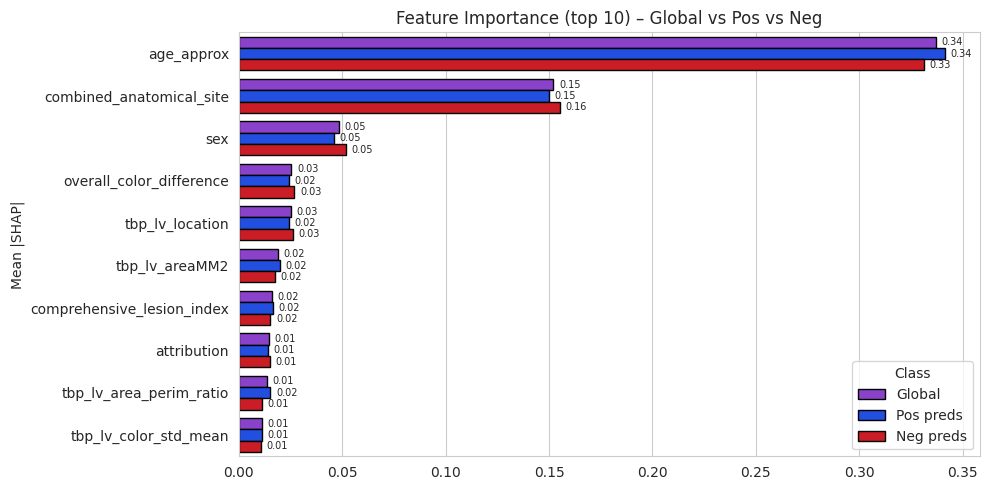

In [149]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_topk_grouped_raw(
    global_imp, pos_imp, neg_imp, k=10, figsize=(10, 5), out_path=None
):
    # Ranking
    items = sorted(global_imp.items(), key=lambda kv: kv[1], reverse=True)[:k]
    names = [k for k, _ in items]

    df = pd.DataFrame({
        "feature": names,
        "Global": [global_imp.get(n, 0.0) for n in names],
        "Pos preds": [pos_imp.get(n, 0.0) for n in names],
        "Neg preds": [neg_imp.get(n, 0.0) for n in names],
    })

    df_melt = df.melt(id_vars="feature", var_name="Class", value_name="Importance")

    plt.figure(figsize=figsize)
    ax = sns.barplot(
        data=df_melt,
        y="feature", x="Importance", hue="Class",
        palette=(sns.color_palette("bright")[4], sns.color_palette("bright")[0], sns.color_palette("bright")[3]),
        edgecolor="black"
    )

    # Add value labels
    for container in ax.containers:
        ax.bar_label(container, fmt="{:.2f}", padding=4, fontsize=7)

    # plt.xticks(rotation=45, ha="right")
    plt.ylabel("Mean |SHAP|")
    plt.xlabel("")
    plt.title(f"Feature Importance (top {k}) – Global vs Pos vs Neg")
    plt.tight_layout()

    if out_path:
        plt.savefig(out_path, dpi=300, bbox_inches="tight")

    plt.show()

plot_topk_grouped_raw(
    global_importance_raw,
    pos_importance_raw,
    neg_importance_raw,
    k=10,
    out_path="shap_grouped_raw_top10_glob_pos_neg.png",
)

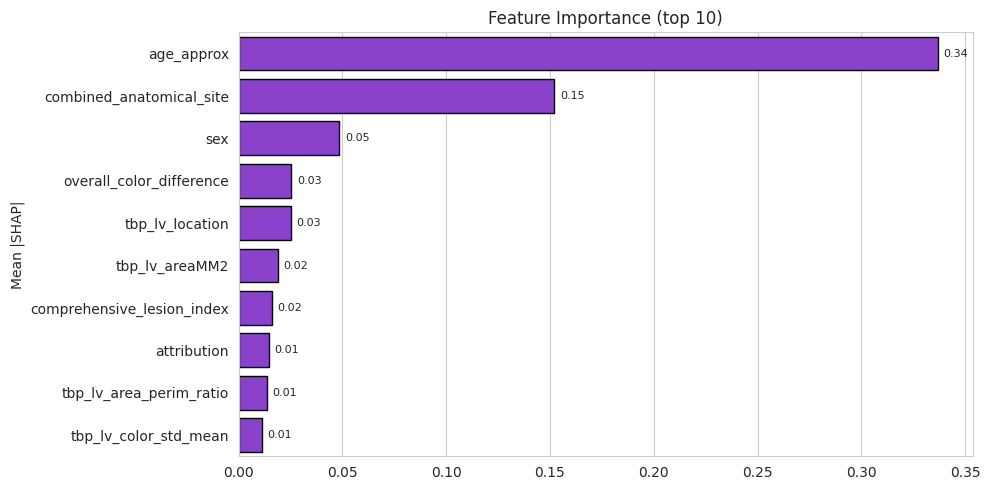

In [153]:
def plot_topk_grouped_raw(
    global_imp, pos_imp, neg_imp, k=10, figsize=(10, 5), out_path=None
):
    # Ranking
    items = sorted(global_imp.items(), key=lambda kv: kv[1], reverse=True)[:k]
    names = [k for k, _ in items]

    df = pd.DataFrame({
        "feature": names,
        "Global": [global_imp.get(n, 0.0) for n in names],
    })

    df_melt = df.melt(id_vars="feature", var_name="Class", value_name="Importance")

    plt.figure(figsize=figsize)
    ax = sns.barplot(
        data=df_melt,
        y="feature", x="Importance", hue="Class",
        palette=(sns.color_palette("bright")[4], sns.color_palette("bright")[0]),
        edgecolor="black",
        legend=False
    )

    # Add value labels
    for container in ax.containers:
        ax.bar_label(container, fmt="{:.2f}", padding=4, fontsize=8)

    # plt.xticks(rotation=45, ha="right")
    plt.ylabel("Mean |SHAP|")
    plt.xlabel("")
    plt.title(f"Feature Importance (top {k})")
    plt.tight_layout()

    if out_path:
        plt.savefig(out_path, dpi=300, bbox_inches="tight")

    plt.show()

plot_topk_grouped_raw(
    global_importance_raw,
    pos_importance_raw,
    neg_importance_raw,
    k=10,
    out_path="shap_grouped_raw_top10_glob.png",
)

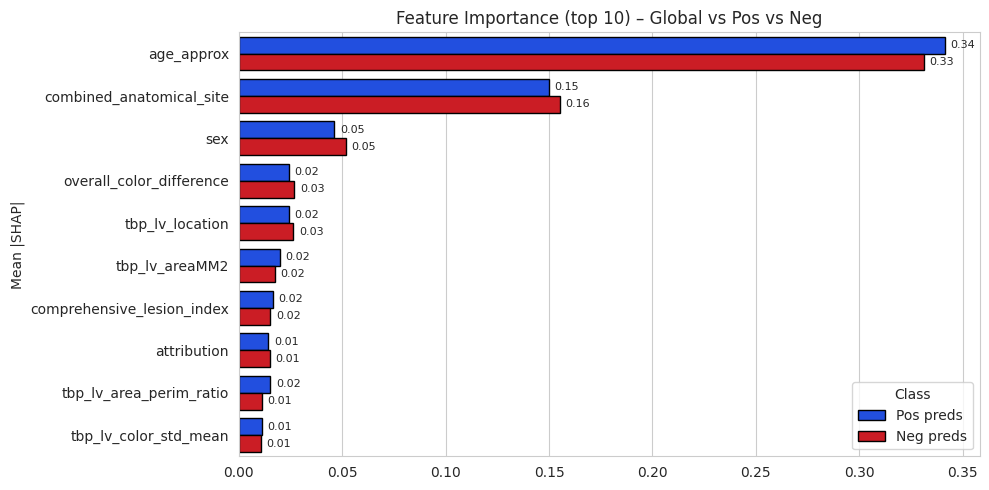

In [134]:
def plot_topk_grouped_raw(
    global_imp, pos_imp, neg_imp, k=10, figsize=(10, 5), out_path=None
):
    # Ranking
    items = sorted(global_imp.items(), key=lambda kv: kv[1], reverse=True)[:k]
    names = [k for k, _ in items]

    df = pd.DataFrame({
        "feature": names,
        "Pos preds": [pos_imp.get(n, 0.0) for n in names],
        "Neg preds": [neg_imp.get(n, 0.0) for n in names],
    })

    df_melt = df.melt(id_vars="feature", var_name="Class", value_name="Importance")

    plt.figure(figsize=figsize)
    ax = sns.barplot(
        data=df_melt,
        y="feature", x="Importance", hue="Class",
        palette=(sns.color_palette("bright", 5)[0], sns.color_palette("bright", 5)[3]),
        edgecolor="black"
    )

    # Add value labels
    for container in ax.containers:
        ax.bar_label(container, fmt="{:.2f}", padding=4, fontsize=8)

    # plt.xticks(rotation=45, ha="right")
    plt.ylabel("Mean |SHAP|")
    plt.xlabel("")
    plt.title(f"Feature Importance (top {k}) – Global vs Pos vs Neg")
    plt.tight_layout()

    if out_path:
        plt.savefig(out_path, dpi=300, bbox_inches="tight")

    plt.show()

plot_topk_grouped_raw(
    global_importance_raw,
    pos_importance_raw,
    neg_importance_raw,
    k=10,
    out_path="shap_grouped_raw_top10_pos_neg.png",
)

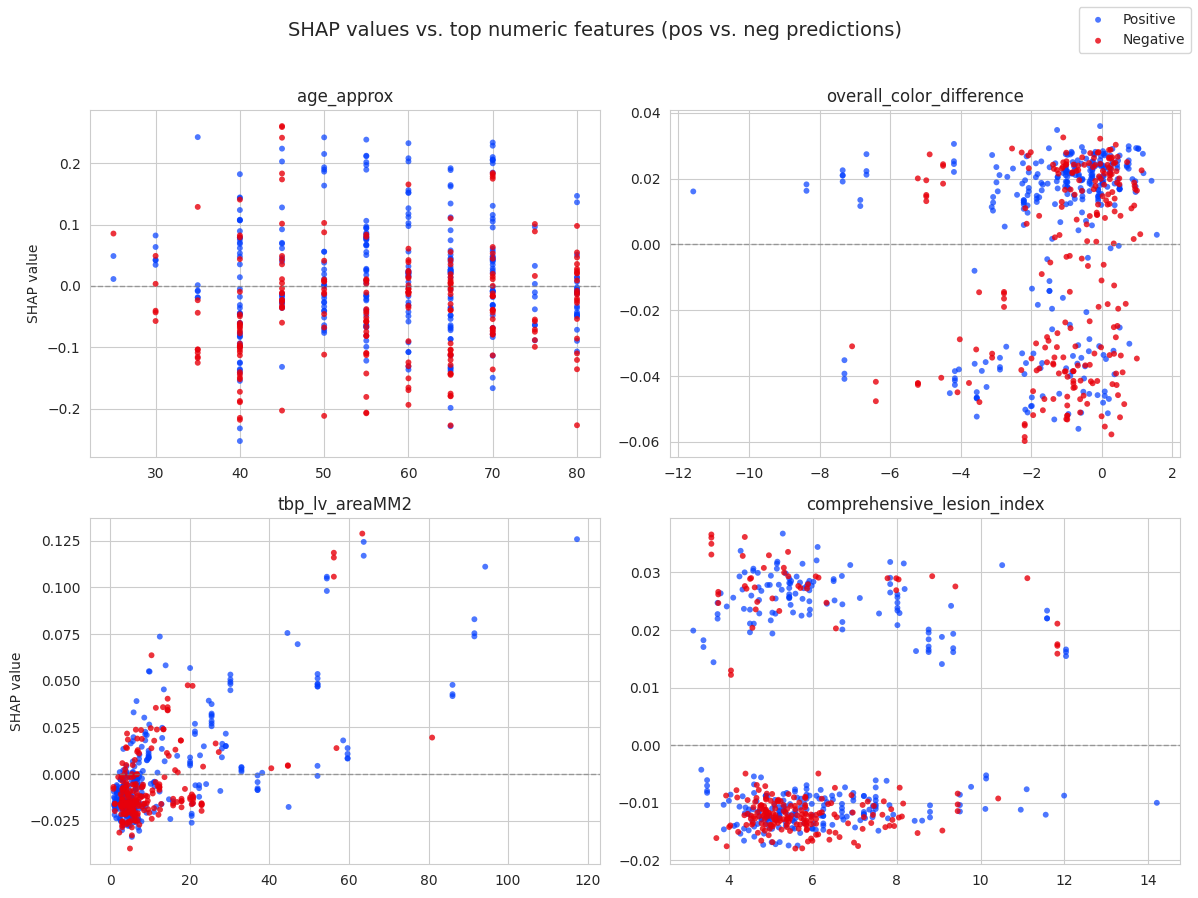

In [128]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")


def encoded_indices_for_raw(encoded_feature_names, feat_name):
    idxs = []
    for j, name in enumerate(encoded_feature_names):
        if "__" in name:
            if name.split("__", 1)[0] == feat_name:
                idxs.append(j)
        elif name.startswith(f"{feat_name}_bin_"):
            idxs.append(j)
        elif name == feat_name:
            idxs.append(j)
    return np.array(idxs, dtype=int)


def select_top_numeric_features(global_importance_raw, raw_batch_df, k=4):
    """Return top-k raw features among those that are numeric-only."""
    numeric_feats = [
        f for f in global_importance_raw.keys()
        if f in raw_batch_df.columns and raw_batch_df[f].dtype.kind in "if"  # int or float
    ]

    ordered = sorted(
        numeric_feats,
        key=lambda name: global_importance_raw[name],
        reverse=True,
    )

    return ordered[:k]


def plot_shap_scatter_top4_numeric(
    shap_vals,
    preds,
    encoded_feature_names,
    global_importance_raw,
    raw_batch_df,
    explained_indices,
    positive_threshold=0.5,
    out_path=None,
):
    # Pick top-4 numeric raw features
    top_feats = select_top_numeric_features(global_importance_raw, raw_batch_df, k=4)

    pred_scores = preds[:, 0]
    pos_mask = pred_scores >= positive_threshold
    neg_mask = ~pos_mask

    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    axes = axes.ravel()
    fig.suptitle(
        "SHAP values vs. top numeric features (pos vs. neg predictions)",
        fontsize=14,
    )

    # bright colors for pos/neg
    colors = sns.color_palette("bright", 5)
    pos_color, neg_color = colors[0], colors[3]

    for i, (ax, feat_name) in enumerate(zip(axes, top_feats)):
        # encoded dims for this feature
        enc_idx = encoded_indices_for_raw(encoded_feature_names, feat_name)
        if enc_idx.size == 0:
            ax.set_title(f"{feat_name} (no encoded dims)")
            ax.axis("off")
            continue

        # aggregate SHAP for this feature
        shap_feat = shap_vals[:, enc_idx].sum(axis=1)

        # raw feature values for explained samples
        raw_vals_batch = raw_batch_df[feat_name].values
        raw_vals = raw_vals_batch[explained_indices]

        # split pos/neg
        x_pos = raw_vals[pos_mask]
        y_pos = shap_feat[pos_mask]
        x_neg = raw_vals[neg_mask]
        y_neg = shap_feat[neg_mask]

        ax.scatter(
            x_pos, y_pos,
            s=18, marker="o", alpha=0.7,
            label="Positive", color=pos_color, edgecolors="none",
        )
        ax.scatter(
            x_neg, y_neg,
            s=18, marker="o", alpha=0.8,
            label="Negative", color=neg_color, edgecolors="none",
        )

        # zero-line for SHAP reference
        ax.axhline(0.0, color="grey", linewidth=1, linestyle="--", alpha=0.7)

        ax.set_title(feat_name)

        # Only left column gets y-label
        if i in (0, 2):
            ax.set_ylabel("SHAP value")

        # x-labels optional; if you want them only on bottom row, uncomment:
        # if i in (2, 3):
        #     ax.set_xlabel(feat_name)

    # hide unused axes if fewer than 4 numeric features
    for i in range(len(top_feats), 4):
        axes[i].axis("off")

    # single legend
    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper right")

    fig.tight_layout(rect=[0, 0, 1, 0.96])

    if out_path is not None:
        fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()

batch_size = features.shape[0]
raw_batch = validation_df.iloc[:batch_size][FEAT_COLS].reset_index(drop=True)

plot_shap_scatter_top4_numeric(
    shap_vals=shap_vals,
    preds=preds,
    encoded_feature_names=encoded_feature_names,
    global_importance_raw=global_importance_raw,
    raw_batch_df=raw_batch,
    explained_indices=stats["explained_indices"],
    positive_threshold=0.5,
    out_path="shap_top4_numeric_grid.png",
)

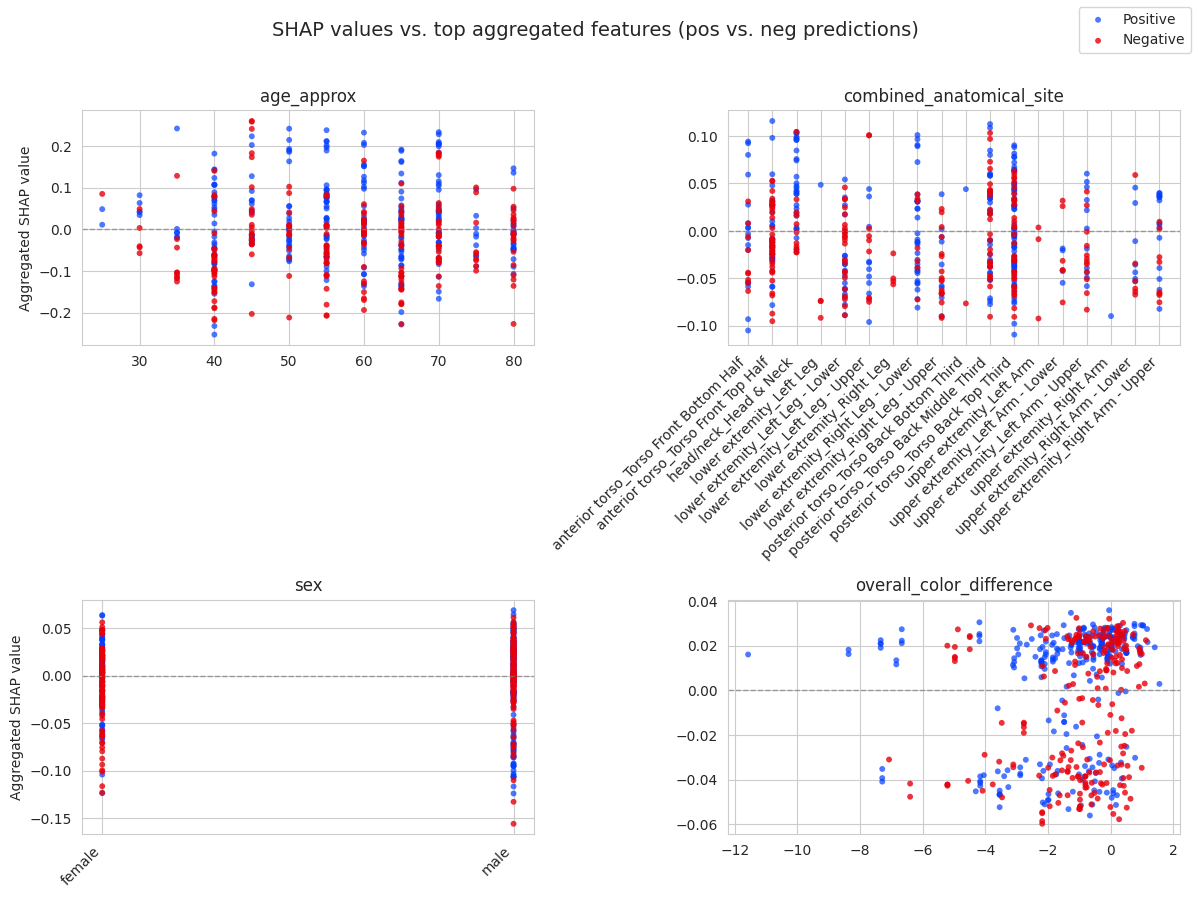

In [122]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")


def encoded_indices_for_raw(encoded_feature_names, feat_name):
    idxs = []
    for j, name in enumerate(encoded_feature_names):
        if "__" in name:
            if name.split("__", 1)[0] == feat_name:
                idxs.append(j)
        elif name.startswith(f"{feat_name}_bin_"):  # es: age_approx_bin_k
            idxs.append(j)
        elif name == feat_name:
            idxs.append(j)
    return np.array(idxs, dtype=int)


def plot_shap_scatter_top4_grid(
    shap_vals,
    preds,
    encoded_feature_names,
    global_importance_raw,
    raw_batch_df,
    explained_indices,
    positive_threshold=0.5,
    out_path=None,
):
    # top-4 raw features by global importance
    top_feats = [
        name for name, _ in sorted(
            global_importance_raw.items(),
            key=lambda kv: kv[1],
            reverse=True,
        )[:4]
    ]

    pred_scores = preds[:, 0]
    pos_mask = pred_scores >= positive_threshold
    neg_mask = ~pos_mask

    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    axes = axes.ravel()
    fig.suptitle(
        "SHAP values vs. top aggregated features (pos vs. neg predictions)",
        fontsize=14,
    )

    # pastel colors for pos/neg
    colors = sns.color_palette("bright", 5)
    pos_color, neg_color = colors[0], colors[3]

    for i, (ax, feat_name) in enumerate(zip(axes, top_feats)):
        enc_idx = encoded_indices_for_raw(encoded_feature_names, feat_name)
        if enc_idx.size == 0:
            ax.set_title(f"{feat_name} (no encoded idx)")
            ax.axis("off")
            continue

        # aggregated SHAP per feature (per instance)
        shap_feat = shap_vals[:, enc_idx].sum(axis=1)  # (n_explain,)

        # raw values for the same batch / indices
        raw_vals_batch = raw_batch_df[feat_name].values
        raw_vals = raw_vals_batch[explained_indices]

        is_numeric = raw_batch_df[feat_name].dtype.kind in "if"

        if is_numeric:
            x_vals = raw_vals
            x_pos = x_vals[pos_mask]
            y_pos = shap_feat[pos_mask]
            x_neg = x_vals[neg_mask]
            y_neg = shap_feat[neg_mask]

            ax.scatter(
                x_pos, y_pos,
                s=18, marker="o", alpha=0.7,
                label="Positive", color=pos_color, edgecolors="none",
            )
            ax.scatter(
                x_neg, y_neg,
                s=18, marker="o", alpha=0.8,
                label="Negative", color=neg_color,  edgecolors="none",
            )

        else:
            # categorical: map categories -> integers 0..N-1
            cats, inv = np.unique(raw_vals, return_inverse=True)
            x_vals = inv

            x_pos = x_vals[pos_mask]
            y_pos = shap_feat[pos_mask]
            x_neg = x_vals[neg_mask]
            y_neg = shap_feat[neg_mask]

            ax.scatter(
                x_pos, y_pos,
                s=18, marker="o", alpha=0.7,
                label="Positive", color=pos_color, edgecolors="none",
            )
            ax.scatter(
                x_neg, y_neg,
                s=18, marker="o", alpha=0.8,
                label="Negative", color=neg_color, edgecolors="none",
            )

            ax.set_xticks(np.arange(len(cats)))
            ax.set_xticklabels(cats, rotation=45, ha="right")

        # zero-line for SHAP reference
        ax.axhline(0.0, color="grey", linewidth=1, linestyle="--", alpha=0.7)

        ax.set_title(feat_name)

        # Only bottom row gets x-label
        # if i in (2, 3):
        #     ax.set_xlabel("Raw feature value")
        # Only left column gets y-label
        if i in (0, 2):
            ax.set_ylabel("Aggregated SHAP value")

    # hide unused axes if fewer than 4 features
    for k in range(len(top_feats), 4):
        axes[k].axis("off")

    # shared legend
    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper right")

    fig.tight_layout(rect=[0, 0, 1, 0.96])

    if out_path is not None:
        fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()

plot_shap_scatter_top4_grid(
    shap_vals=shap_vals,
    preds=preds,
    encoded_feature_names=encoded_feature_names,
    global_importance_raw=global_importance_raw,
    raw_batch_df=raw_batch,
    explained_indices=stats["explained_indices"],
    positive_threshold=0.5,
    out_path="shap_top4_scatter_grid.png",
)